# Filtro inverso de Shirzad-Ghaleroudkhani y Gül (2021), paso a paso

**Artículo:** Shirzad-Ghaleroudkhani, N. y Gül, M. (2021). Enhanced inverse filtering for drive-by frequency identification of bridges using smartphones. *Smart Cities*, 4, 499–513.

**El método en una frase:** se usa el espectro de la aceleración del carro **fuera del puente** para quitar del espectro **sobre el puente** lo que viene del carro y de la carretera, y que quede a la vista la frecuencia del puente.

En este notebook se aplica el método tal como lo describe el artículo a los datos del proyecto (`p03-random-bridges-traffic`: 300 puentes aleatorios, 5 viajes por puente, rugosidad clase A, B o C). Primero se sigue un viaje paso a paso (el viaje 728) y al final se aplica a todos los viajes.

## Índice

1. Librerías y datos
2. La idea del método
3. Paso 1: separar fuera y sobre el puente
4. Paso 2: tramo sobre el puente de al menos 3 s
5. Paso 3: ventanas de 3 s fuera del puente
6. Paso 4: elegir la ventana con la misma rugosidad (SRC)
7. Paso 5: espectros
8. Paso 6: filtro inverso
9. Paso 7: aplicar el filtro y buscar el pico
10. Control: el mismo procedimiento sin el puente
11. Todos los viajes
12. Conclusiones

## 1. Librerías y datos

Se leen del archivo de p03 solo las señales que usa el método. La parte del puente (`bridge_part`) **no la usa el método**: solo sirve para el control de la sección 10.

In [1]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. File of the p03 dataset (300 random bridges, 5 trips each)
FILE = "datasets/p03-random-bridges-traffic/data/main_padded.h5"
FS = 200.0   # sampling rate (Hz)

# 2. Read the signals (one row per trip)
f = h5py.File(FILE, "r")
measured = f["measured"][:]          # phone acceleration (m/s^2)
segment = f["segment"][:]            # 0 = road before, 1 = bridge, 2 = road after
valid = f["valid_mask"][:] == 1      # True where the trip has data (rows are padded with zeros)

# 3. Part of the phone signal that comes from the bridge (only for the control)
bridge_part = f["components/bridge_mode_1"][:]
bridge_part = bridge_part + f["components/bridge_mode_2"][:]
bridge_part = bridge_part + f["components/bridge_mode_3"][:]
bridge_part = bridge_part + f["components/bridge_higher_modes"][:]

# 4. Information of each trip
f1 = f["metadata/f1"][:]             # first bridge frequency (Hz)
speed = f["metadata/speed"][:]       # vehicle speed (m/s), constant in each trip
span = f["metadata/span"][:]         # bridge length (m)
f.close()

print("Trips:", len(f1))
print("Speed:", round(speed.min(), 1), "to", round(speed.max(), 1), "m/s")
print("Bridge length:", round(span.min(), 1), "to", round(span.max(), 1), "m")
print("f1:", round(f1.min(), 2), "to", round(f1.max(), 2), "Hz")

Trips: 1500
Speed: 5.0 to 25.0 m/s
Bridge length: 15.0 to 60.0 m
f1: 1.28 to 10.36 Hz


## 2. La idea del método

El teléfono mide la vibración del carro. Esa vibración depende sobre todo del carro (suspensión, velocidad) y de la rugosidad de la carretera. Sobre el puente se suma, además, la vibración del puente.

Si fuera y sobre el puente el carro, la velocidad y la rugosidad son iguales, el espectro fuera del puente $X$ contiene "todo lo que no es puente". El artículo define el filtro inverso como (Ecs. 2 y 3 del artículo):

$$F(f) = \frac{1}{X(f)} \tag{1}$$

$$Y_f(f) = Y(f)\,F(f) = \frac{Y(f)}{X(f)} \tag{2}$$

- $X(f)$: magnitud del espectro de la aceleración **fuera** del puente.
- $Y(f)$: magnitud del espectro de la aceleración **sobre** el puente.
- $F(f)$: filtro inverso.
- $Y_f(f)$: espectro sobre el puente ya filtrado; su pico más alto debería ser la frecuencia del puente.

**En palabras (lectura simplificada, no está en el artículo):** si sobre el puente $Y \approx X + B$, con $B$ la parte del puente, entonces $Y/X \approx 1 + B/X$. Donde no hay puente el cociente vale cerca de 1, y en la frecuencia del puente sube por encima de 1. **Cuánto sube depende de cuánto pesa el puente frente a lo demás ($B/X$).**

**Tabla 1.** Pasos del método en el artículo y cómo se aplican aquí.

| Paso | Artículo (2021) | Aquí (p03) |
|---|---|---|
| 1. Separar fuera y sobre el puente | GPS del teléfono (1 Hz) | Columna `segment` del dataset |
| 2. Tramo sobre el puente | Velocidad constante: 4 lecturas de GPS iguales (≥ 3 s), en rangos de 2.5 km/h | La velocidad es constante en cada viaje; se exigen ≥ 3 s sobre el puente |
| 3. Ventanas fuera del puente | Ventanas de 3 s con 25 % de traslape, de una base de datos del mismo carro, a la misma velocidad | Ventanas de 3 s con 25 % de traslape de la carretera del mismo viaje (cada viaje de p03 tiene su propio carro) |
| 4. Elegir la ventana | La de SRC más parecido; se descarta si difiere más de 5 % | Igual |
| 5. Espectros | Magnitud de la DFT | Igual (con relleno de ceros, ver sección 7) |
| 6. Filtro | $F = 1/X$ (Ec. 1) | Igual |
| 7. Resultado | $Y_f = Y/X$ (Ec. 2); se mira el pico más alto | Igual; pico más alto entre 1 y 20 Hz |

## 3. Paso 1: separar fuera y sobre el puente

En el artículo los tramos se separan con el GPS. Aquí el dataset ya dice en qué tramo está cada muestra (`segment`).

Se usa como ejemplo el **viaje 728**: es un viaje típico de p03, porque cerca de f1 su parte del puente está 21.5 dB por debajo del resto de la señal, que es la mediana de todos los viajes.

In [2]:
TRIP = 728

def trip_parts(signal, i):
    # Split trip i into road before, bridge and road after (only samples with data)
    road_before = signal[i][(segment[i] == 0) & valid[i]]
    on_bridge = signal[i][(segment[i] == 1) & valid[i]]
    road_after = signal[i][(segment[i] == 2) & valid[i]]
    return road_before, on_bridge, road_after

road_before, on_bridge, road_after = trip_parts(measured, TRIP)

print("Bridge length:", round(span[TRIP], 1), "m   speed:", round(speed[TRIP], 2), "m/s   f1:", round(f1[TRIP], 2), "Hz")
print("Road before:", len(road_before) / FS, "s")
print("On the bridge:", len(on_bridge) / FS, "s")
print("Road after:", len(road_after) / FS, "s")

Bridge length: 44.9 m   speed: 9.47 m/s   f1: 2.23 Hz
Road before: 10.565 s
On the bridge: 4.745 s
Road after: 10.565 s


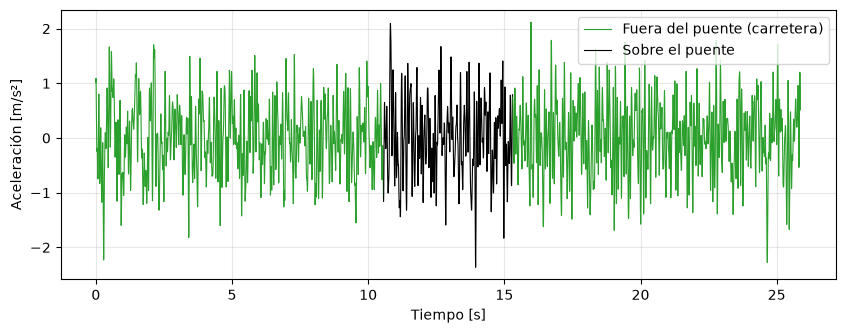

In [3]:
# Time axis of each part (one after the other)
t_before = np.arange(len(road_before)) / FS
t_bridge = t_before[-1] + (np.arange(len(on_bridge)) + 1) / FS
t_after = t_bridge[-1] + (np.arange(len(road_after)) + 1) / FS

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t_before, road_before, color="tab:green", lw=0.8, label="Fuera del puente (carretera)")
ax.plot(t_bridge, on_bridge, color="black", lw=0.8, label="Sobre el puente")
ax.plot(t_after, road_after, color="tab:green", lw=0.8)
ax.set_xlabel("Tiempo [s]")
ax.set_ylabel("Aceleración [m/s²]")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.show()

**Figura 1.** Aceleración medida por el teléfono en el viaje 728 (puente de 44.9 m, 9.47 m/s, f1 = 2.23 Hz). En verde, la carretera antes y después del puente; en negro, el tramo sobre el puente.

A simple vista no hay diferencia entre la carretera y el puente: la señal está dominada por el carro y la rugosidad.

## 4. Paso 2: tramo sobre el puente de al menos 3 s

El artículo usa solo tramos a velocidad constante de al menos 3 s (cuatro lecturas iguales del GPS). En p03 la velocidad es constante en todo el viaje, así que lo único que limita es la duración del cruce:

$$T_{puente} = \frac{L}{v} \tag{3}$$

- $T_{puente}$: tiempo que el carro está sobre el puente [s].
- $L$: largo del puente [m].
- $v$: velocidad del carro [m/s].

Con puentes de 15–60 m y velocidades de 5–25 m/s, muchos cruces duran menos de 3 s.

In [4]:
WINDOW = int(3 * FS)    # 3 s = 600 samples

# Count the trips whose bridge crossing lasts at least 3 s
long_enough = 0
too_short = 0
for i in range(len(f1)):
    n_bridge = np.sum((segment[i] == 1) & valid[i])
    if n_bridge >= WINDOW:
        long_enough = long_enough + 1
    else:
        too_short = too_short + 1

table = pd.DataFrame([
    {"Viajes": "Con ≥ 3 s sobre el puente (se pueden usar)", "Número": long_enough, "%": round(100 * long_enough / len(f1), 1)},
    {"Viajes": "Con < 3 s sobre el puente (se descartan)", "Número": too_short, "%": round(100 * too_short / len(f1), 1)},
    {"Viajes": "Total", "Número": len(f1), "%": 100.0},
])
table

,Viajes,Número,%
0,Con ≥ 3 s sobre el puente (se pueden usar),617,41.1
1,Con < 3 s sobre el puente (se descartan),883,58.9
2,Total,1500,100.0


**Tabla 2.** Viajes de p03 que cumplen la condición del artículo (al menos 3 s sobre el puente). El viaje 728 dura 4.7 s sobre el puente, así que se puede usar.

## 5. Paso 3: ventanas de 3 s fuera del puente

El artículo arma una base de datos con ventanas de 3 s de la señal fuera del puente, con 25 % de traslape (cada ventana empieza 2.25 s después de la anterior), del mismo carro y a la misma velocidad.

En p03 cada viaje tiene su propio carro, así que la única carretera con el mismo carro y la misma velocidad es la del **mismo viaje** (antes y después del puente). Las ventanas no cruzan el puente.

In [5]:
STEP = int(0.75 * WINDOW)   # 25 % overlap: next window starts 2.25 s later

def road_windows(signal, i):
    # All 3 s windows of the road before and after the bridge of trip i
    road_before, on_bridge, road_after = trip_parts(signal, i)
    windows = []
    for part_name, road in [("antes", road_before), ("después", road_after)]:
        start = 0
        while start + WINDOW <= len(road):
            windows.append({"part": part_name, "start": start / FS, "signal": road[start:start + WINDOW]})
            start = start + STEP
    return windows

windows = road_windows(measured, TRIP)
print("Number of 3 s windows off the bridge:", len(windows))

Number of 3 s windows off the bridge: 8


## 6. Paso 4: elegir la ventana con la misma rugosidad (SRC)

El artículo mide la rugosidad con el **SRC** (*surface roughness coefficient*), la media de la aceleración al cuadrado:

$$SRC = \frac{1}{N}\sum_{n=1}^{N} a[n]^2 \tag{4}$$

- $a[n]$: aceleración medida en la muestra $n$ [m/s²].
- $N$: número de muestras del tramo.

Se calcula el SRC del tramo sobre el puente y el de cada ventana, y se elige la ventana con la diferencia relativa más pequeña:

$$\Delta_{SRC} = \frac{|SRC_{ventana} - SRC_{puente}|}{SRC_{puente}} \tag{5}$$

Si la mejor ventana difiere más de 5 %, el artículo descarta el tramo.

In [6]:
def src(x):
    # Surface roughness coefficient: mean square acceleration (Eq. 4)
    return np.mean(x ** 2)

src_bridge = src(on_bridge)

# SRC of each window and its relative difference to the bridge (Eq. 5)
rows = []
for w in windows:
    difference = abs(src(w["signal"]) - src_bridge) / src_bridge
    rows.append({"Carretera": w["part"], "Inicio [s]": w["start"],
                 "SRC [(m/s²)²]": round(float(src(w["signal"])), 3), "Diferencia [%]": round(float(100 * difference), 1)})
table = pd.DataFrame(rows)

# The chosen window is the one with the smallest difference
best = int(np.argmin(table["Diferencia [%]"]))
off_bridge = windows[best]["signal"]

print("SRC on the bridge:", round(src_bridge, 3), "(m/s^2)^2")
print("Chosen window:", best, "| difference:", table["Diferencia [%]"][best], "%")
table

SRC on the bridge: 0.494 (m/s^2)^2
Chosen window: 0 | difference: 0.8 %


,Carretera,Inicio [s],SRC [(m/s²)²],Diferencia [%]
0,antes,0.00,0.489,0.8
1,antes,2.25,0.343,30.5
2,antes,4.50,0.377,23.6
3,antes,6.75,0.372,24.7
4,después,0.00,0.431,12.6
5,después,2.25,0.471,4.5
6,después,4.50,0.372,24.7
7,después,6.75,0.386,21.8


**Tabla 3.** Ventanas de 3 s fuera del puente del viaje 728, su SRC (Ec. 4) y su diferencia con el SRC sobre el puente (Ec. 5). Se elige la de menor diferencia, que queda por debajo del 5 % del artículo.

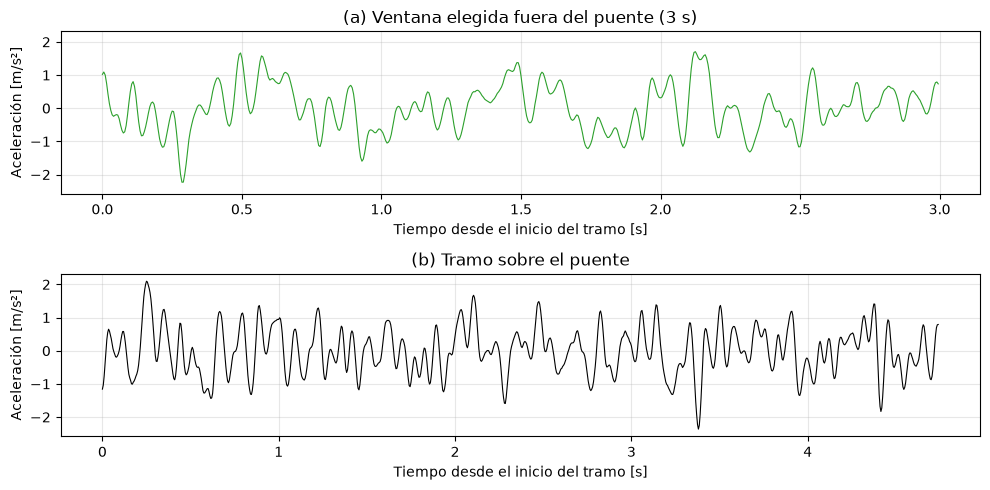

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharey=True)
ax[0].plot(np.arange(len(off_bridge)) / FS, off_bridge, color="tab:green", lw=0.8)
ax[0].set_title("(a) Ventana elegida fuera del puente (3 s)")
ax[1].plot(np.arange(len(on_bridge)) / FS, on_bridge, color="black", lw=0.8)
ax[1].set_title("(b) Tramo sobre el puente")
for a in ax:
    a.set_xlabel("Tiempo desde el inicio del tramo [s]")
    a.set_ylabel("Aceleración [m/s²]")
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Figura 2.** Las dos señales que entran al método en el viaje 728: (a) la ventana fuera del puente con el SRC más parecido y (b) el tramo sobre el puente.

## 7. Paso 5: espectros

El artículo usa la magnitud de la transformada discreta de Fourier (DFT):

$$|X[k]| = \left|\sum_{n=0}^{N-1} x[n]\, e^{-j 2\pi k n / N}\right|, \qquad f_k = \frac{k\, f_s}{N} \tag{6}$$

- $x[n]$: señal (la ventana fuera del puente, o el tramo sobre el puente).
- $N$: largo de la DFT; $k$: índice de la frecuencia $f_k$.
- $f_s$: frecuencia de muestreo (200 Hz).

El artículo no dice el largo de la DFT. Aquí las dos señales se rellenan con ceros hasta $N$ = 4096 muestras (20.5 s), para que $X$ e $Y$ tengan las mismas frecuencias y se puedan dividir. Rellenar con ceros no agrega información: solo dibuja más puntos del mismo espectro (cada 0.05 Hz).

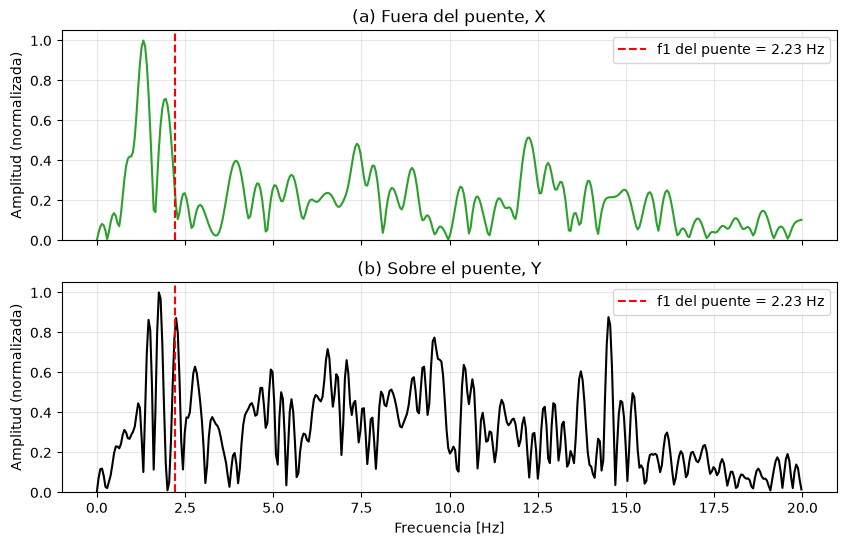

In [8]:
N_FFT = 4096
freqs = np.fft.rfftfreq(N_FFT, 1 / FS)
SHOW = freqs <= 20.0    # the article plots 0-20 Hz

def spectrum(x):
    # Magnitude of the DFT, zero padded to N_FFT samples (Eq. 6)
    return np.abs(np.fft.rfft(x, N_FFT))

def normalized(s):
    # Divide by the maximum in 0-20 Hz, as in the article's figures
    return s[SHOW] / np.max(s[SHOW])

X = spectrum(off_bridge)
Y = spectrum(on_bridge)

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(freqs[SHOW], normalized(X), color="tab:green")
ax[0].set_title("(a) Fuera del puente, X")
ax[1].plot(freqs[SHOW], normalized(Y), color="black")
ax[1].set_title("(b) Sobre el puente, Y")
for a in ax:
    a.axvline(f1[TRIP], color="red", ls="--", label="f1 del puente = " + str(round(f1[TRIP], 2)) + " Hz")
    a.set_ylabel("Amplitud (normalizada)")
    a.set_ylim(0, 1.05)
    a.grid(alpha=0.3)
    a.legend(loc="upper right")
ax[1].set_xlabel("Frecuencia [Hz]")
plt.show()

**Figura 3.** Espectros del viaje 728 (Ec. 6), cada uno dividido por su máximo entre 0 y 20 Hz, como en las figuras del artículo. (a) Ventana fuera del puente; (b) tramo sobre el puente. La línea roja marca f1.

Los dos espectros tienen muchos picos y ninguno destaca en f1: ambos están dominados por el carro y la rugosidad.

## 8. Paso 6: filtro inverso

El filtro es el inverso del espectro fuera del puente (Ec. 1). Donde $X$ es grande (frecuencias que el carro y la carretera excitan mucho), $F$ es pequeño, y al revés.

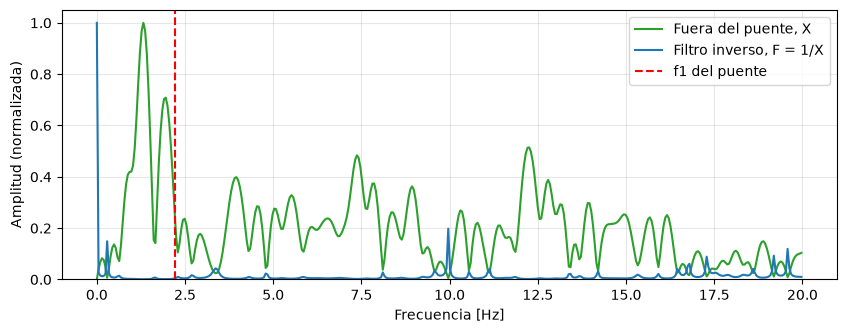

Frequency where F is largest: 0.0 Hz


In [9]:
F = 1 / X   # inverse filter (Eq. 1)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(freqs[SHOW], normalized(X), color="tab:green", label="Fuera del puente, X")
ax.plot(freqs[SHOW], normalized(F), color="tab:blue", label="Filtro inverso, F = 1/X")
ax.axvline(f1[TRIP], color="red", ls="--", label="f1 del puente")
ax.set_xlabel("Frecuencia [Hz]")
ax.set_ylabel("Amplitud (normalizada)")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.show()

print("Frequency where F is largest:", freqs[SHOW][np.argmax(F[SHOW])], "Hz")

**Figura 4.** Espectro fuera del puente (verde) y filtro inverso (azul) del viaje 728, normalizados como en la Fig. 1a del artículo.

El filtro tiene un pico muy alto a muy baja frecuencia, donde $X$ es casi cero (dividir entre casi cero da un número muy grande). Lo mismo se ve en la Fig. 1a del artículo. Por eso, en el paso 7 el pico se busca entre 1 y 20 Hz (todas las f1 de p03 están entre 1.3 y 10.4 Hz).

## 9. Paso 7: aplicar el filtro y buscar el pico

Se multiplica el espectro sobre el puente por el filtro (Ec. 2) y se busca la frecuencia del pico más alto entre 1 y 20 Hz. Se considera un acierto si cae a menos de 10 % de f1:

$$\frac{|f_{pico} - f_1|}{f_1} < 0.10 \tag{7}$$

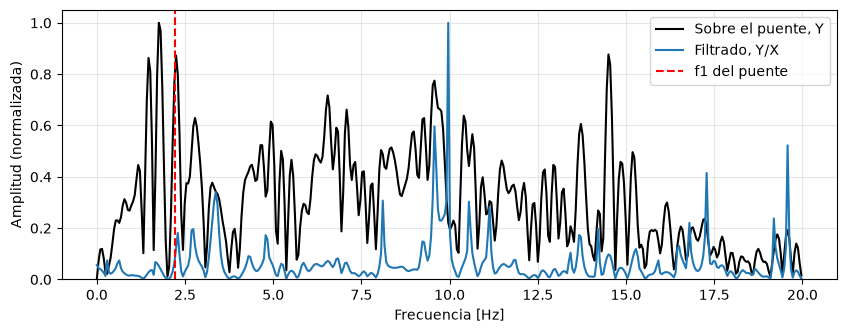

,Espectro,Pico más alto [Hz],f1 [Hz],Acierto (Ec. 7)
0,"Sobre el puente, Y",1.76,2.23,False
1,"Filtrado, Y/X",9.96,2.23,False


In [10]:
Y_filtered = Y * F   # filtered on-bridge spectrum (Eq. 2)

SEARCH = (freqs >= 1.0) & (freqs <= 20.0)

def highest_peak(s):
    # Frequency of the highest value between 1 and 20 Hz
    return freqs[SEARCH][np.argmax(s[SEARCH])]

def is_hit(f_peak, f_true):
    # Peak within 10 % of the true frequency (Eq. 7)
    return abs(f_peak - f_true) / f_true < 0.10

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(freqs[SHOW], normalized(Y), color="black", label="Sobre el puente, Y")
ax.plot(freqs[SHOW], normalized(Y_filtered), color="tab:blue", label="Filtrado, Y/X")
ax.axvline(f1[TRIP], color="red", ls="--", label="f1 del puente")
ax.set_xlabel("Frecuencia [Hz]")
ax.set_ylabel("Amplitud (normalizada)")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.show()

table = pd.DataFrame([
    {"Espectro": "Sobre el puente, Y", "Pico más alto [Hz]": round(highest_peak(Y), 2), "f1 [Hz]": round(f1[TRIP], 2), "Acierto (Ec. 7)": is_hit(highest_peak(Y), f1[TRIP])},
    {"Espectro": "Filtrado, Y/X", "Pico más alto [Hz]": round(highest_peak(Y_filtered), 2), "f1 [Hz]": round(f1[TRIP], 2), "Acierto (Ec. 7)": is_hit(highest_peak(Y_filtered), f1[TRIP])},
])
table

**Figura 5.** Espectro sobre el puente sin filtrar (negro) y filtrado (azul) del viaje 728, normalizados como en las Figs. 10 y 11 del artículo.

**Tabla 4.** Pico más alto entre 1 y 20 Hz de cada espectro del viaje 728, comparado con f1.

En este viaje el pico más alto del espectro filtrado no está en f1.

## 10. Control: el mismo procedimiento sin el puente

Para saber si lo que queda en $Y/X$ viene del puente, se repite todo (pasos 1 a 7) con la señal del teléfono **sin su parte del puente** (`measured - bridge_part`). Si el resultado no cambia, el puente no influye en él.

Aquí se juntan los pasos 1 a 7 en una sola función, para aplicarla a cualquier señal y a cualquier viaje.

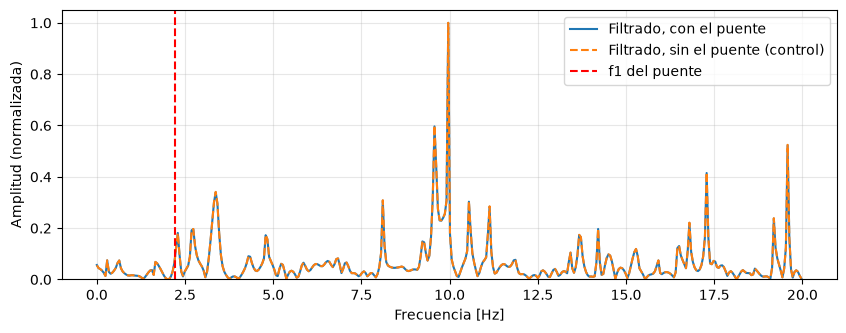

Highest peak with the bridge: 9.96 Hz
Highest peak without the bridge: 9.96 Hz


In [11]:
def inverse_filter(signal, i):
    # Steps 1 to 7 for trip i
    # 1. Split the trip
    road_before, on_bridge, road_after = trip_parts(signal, i)
    # 2-4. Choose the 3 s road window with the closest SRC
    src_bridge = src(on_bridge)
    best_signal = None
    best_difference = None
    for w in road_windows(signal, i):
        difference = abs(src(w["signal"]) - src_bridge) / src_bridge
        if best_difference is None or difference < best_difference:
            best_difference = difference
            best_signal = w["signal"]
    # 5. Spectra
    X = spectrum(best_signal)
    Y = spectrum(on_bridge)
    # 6-7. Inverse filter and filtered spectrum
    Y_filtered = Y / X
    return Y, Y_filtered, best_difference

no_bridge = measured - bridge_part

Y_a, Y_filtered_a, difference_a = inverse_filter(measured, TRIP)     # with the bridge
Y_b, Y_filtered_b, difference_b = inverse_filter(no_bridge, TRIP)    # control: without the bridge

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(freqs[SHOW], normalized(Y_filtered_a), color="tab:blue", label="Filtrado, con el puente")
ax.plot(freqs[SHOW], normalized(Y_filtered_b), color="tab:orange", ls="--", label="Filtrado, sin el puente (control)")
ax.axvline(f1[TRIP], color="red", ls="--", label="f1 del puente")
ax.set_xlabel("Frecuencia [Hz]")
ax.set_ylabel("Amplitud (normalizada)")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.show()

print("Highest peak with the bridge:", round(highest_peak(Y_filtered_a), 2), "Hz")
print("Highest peak without the bridge:", round(highest_peak(Y_filtered_b), 2), "Hz")

**Figura 6.** Espectro filtrado del viaje 728 con el puente (azul) y sin el puente (naranja, control).

Las dos curvas son prácticamente iguales: quitar el puente de la señal no cambia el resultado. Los picos que deja el filtro vienen de la diferencia entre la rugosidad de la ventana fuera del puente y la del tramo sobre el puente, no del puente.

## 11. Todos los viajes

Se aplica el método a todos los viajes con al menos 3 s sobre el puente, con y sin el puente, y se cuenta en cuántos el pico más alto cae en f1 (Ec. 7).

Para saber si un acierto es mejor que el azar: si el pico cayera en cualquier frecuencia entre 1 y 20 Hz con la misma probabilidad, la probabilidad de caer a ±10 % de f1 sería el ancho de esa banda entre el ancho total:

$$P_{azar} = \frac{0.2\, f_1}{20 - 1} \tag{8}$$

In [12]:
rows = []
for i in range(len(f1)):
    # Only trips with at least 3 s on the bridge (step 2)
    n_bridge = np.sum((segment[i] == 1) & valid[i])
    if n_bridge < WINDOW:
        continue

    Y_a, Y_filtered_a, difference = inverse_filter(measured, i)    # with the bridge
    Y_b, Y_filtered_b, _ = inverse_filter(no_bridge, i)            # control

    rows.append({
        "trip": i,
        "src_difference": difference,
        "hit_Y": is_hit(highest_peak(Y_a), f1[i]),
        "hit_Y_control": is_hit(highest_peak(Y_b), f1[i]),
        "hit_filtered": is_hit(highest_peak(Y_filtered_a), f1[i]),
        "hit_filtered_control": is_hit(highest_peak(Y_filtered_b), f1[i]),
        "chance": 0.2 * f1[i] / 19.0,    # Eq. 8
    })
results = pd.DataFrame(rows)

# Summary: all trips, and only those whose SRC difference is at most 5 % (as in the article)
table_rows = []
for name, data in [("Todos (≥ 3 s)", results), ("Solo SRC ≤ 5 %", results[results["src_difference"] <= 0.05])]:
    table_rows.append({
        "Viajes": name,
        "Número": len(data),
        "Y [%]": round(100 * data["hit_Y"].mean(), 1),
        "Y sin puente [%]": round(100 * data["hit_Y_control"].mean(), 1),
        "Y/X [%]": round(100 * data["hit_filtered"].mean(), 1),
        "Y/X sin puente [%]": round(100 * data["hit_filtered_control"].mean(), 1),
        "Azar [%]": round(100 * data["chance"].mean(), 1),
    })
pd.DataFrame(table_rows)

,Viajes,Número,Y [%],Y sin puente [%],Y/X [%],Y/X sin puente [%],Azar [%]
0,Todos (≥ 3 s),617,11.8,9.6,3.1,2.1,2.7
1,Solo SRC ≤ 5 %,420,11.0,8.3,3.6,2.6,2.7


**Tabla 5.** Porcentaje de viajes en que el pico más alto entre 1 y 20 Hz cae a ±10 % de f1 (Ec. 7): espectro sobre el puente sin filtrar ($Y$) y filtrado ($Y/X$), con la señal completa y sin la parte del puente (control), y lo esperado por azar (Ec. 8).

Cómo leer la tabla:

- **Sin filtrar ($Y$):** acierta más que el azar (11.8 % frente a 2.7 %), pero casi lo mismo **sin el puente** (9.6 %). Esos aciertos vienen de picos del carro que caen cerca de f1, no del puente.
- **Filtrado ($Y/X$):** el filtro quita esos picos del carro, pero el acierto queda cerca del azar: 3.1 % (19 de 617 viajes) frente a 2.1 % sin el puente y 2.7 % de azar. La diferencia con el control son 6 viajes.
- Elegir solo los tramos con SRC ≤ 5 % (como en el artículo) no cambia la conclusión: 3.6 % (15 de 420) frente a 2.6 % sin el puente.

## 12. Conclusiones

- El método de 2021 se puede aplicar a p03 sin cambiar el generador: cada viaje tiene carretera antes y después del puente con el mismo carro, la misma velocidad y la misma clase de rugosidad.
- Solo un 41 % de los viajes de p03 cumple la condición de ≥ 3 s sobre el puente (Tabla 2).
- En nuestros datos el filtro inverso **no** hace aparecer f1: el acierto queda cerca del azar y casi igual con y sin el puente (Tabla 5, Figura 6).
- **Por qué (lectura de los resultados):** el filtro divide entre el espectro de *otro* tramo de carretera. Aunque el SRC sea igual, la rugosidad de ese tramo es distinta de la del puente, y sus diferencias pesan mucho más que la parte del puente (−21.5 dB en el viaje típico). El cociente $Y/X$ muestra esas diferencias, no el puente (Ec. 2: $Y/X \approx 1 + B/X$ con $B/X$ muy pequeño).
- **Diferencias con el artículo:** sus puentes miden 214 y 777 m (cruces de 15–56 s) y tienen tráfico; el carro y las condiciones son reales; y los resultados se muestran con ejemplos (Figs. 10 y 11 del artículo), sin un porcentaje de acierto sobre todos los cruces ni un control sin el puente. No sabemos cuánto pesa su puente frente a la rugosidad.